# Q3 et Q4 : prévoir les départs à 8 h

**Q3 :** Il faut dimensionner les camionnettes de rééquilibrage. Combien de trajets partiront de chaque station demain à 8 h ?

**Q4 :** Cette prévision tient-elle les jours particuliers, ou s'écroule-t-elle justement quand on en a besoin ?




In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score, silhouette_score
from sklearn.cluster import KMeans

In [2]:
#charger les données 
stations = pd.read_csv("Data/Citycycle_stations.csv")
trajets = pd.read_csv("Data/Citycycle_trajets.csv")

print("Stations :", stations.shape)
print(stations.dtypes)
print("Trajets :", trajets.shape)
print(trajets.dtypes)

Stations : (140, 7)
station_id                str
longitude_km          float64
latitude_km           float64
type_quartier             str
capacite              float64
altitude_m            float64
interventions_mois      int64
dtype: object
Trajets : (760, 11)
trajet_id              str
station_depart         str
station_arrivee        str
heure                int64
jour                   str
pluie                  str
temperature_c      float64
type_abonnement        str
distance_km        float64
duree_min          float64
type_velo              str
dtype: object


In [3]:
#Afficher
print(stations.head())

  station_id  longitude_km  ...  altitude_m interventions_mois
0      ST200         2.418  ...        46.0                 14
1      ST201         1.861  ...        46.0                  1
2      ST202         2.451  ...        46.0                  3
3      ST203         2.691  ...        42.0                  7
4      ST204         2.365  ...        80.0                  5

[5 rows x 7 columns]


In [4]:
#nettoyage
#valeurs manquantes
print("Valeur manquantes")
print(stations.isna().sum())
print(trajets.isna().sum())
#doublons?
print("nombres de doublons")
print("trajets doublon :",trajets.duplicated().sum())
print("stations doublon :",stations.duplicated().sum())
#drop doublons 

stations = stations.drop_duplicates()
trajets = trajets.drop_duplicates()
#restant 
print("Valeurs restantes")
print(len(trajets))
print(len(stations))

Valeur manquantes
station_id            0
longitude_km          0
latitude_km           0
type_quartier         0
capacite              0
altitude_m            0
interventions_mois    0
dtype: int64
trajet_id           0
station_depart      0
station_arrivee     0
heure               0
jour                0
pluie               0
temperature_c      16
type_abonnement    15
distance_km         0
duree_min           0
type_velo           0
dtype: int64
nombres de doublons
trajets doublon : 60
stations doublon : 0
Valeurs restantes
700
140


On supprime 60 doublons, il reste 700 trajets. Les valeurs manquantes (température, abonnement) et les valeurs bizarres (distance de −1 km, durée de 1 440 min) ne gênent pas : on compte seulement les départs.

In [5]:
#verifier la fiabilité
depart_inconu = trajets[~trajets["station_depart"].isin(stations["station_id"])]
arrive_inconu = trajets[~trajets["station_arrivee"].isin(stations["station_id"])]
print(depart_inconu)
print(arrive_inconu)

Empty DataFrame
Columns: [trajet_id, station_depart, station_arrivee, heure, jour, pluie, temperature_c, type_abonnement, distance_km, duree_min, type_velo]
Index: []
Empty DataFrame
Columns: [trajet_id, station_depart, station_arrivee, heure, jour, pluie, temperature_c, type_abonnement, distance_km, duree_min, type_velo]
Index: []


In [6]:
#verification des types 
print(stations.dtypes)
print(trajets.dtypes)

#float to int 
stations["capacite"] = stations["capacite"].astype(int)

station_id                str
longitude_km          float64
latitude_km           float64
type_quartier             str
capacite              float64
altitude_m            float64
interventions_mois      int64
dtype: object
trajet_id              str
station_depart         str
station_arrivee        str
heure                int64
jour                   str
pluie                  str
temperature_c      float64
type_abonnement        str
distance_km        float64
duree_min          float64
type_velo              str
dtype: object


In [7]:
#resume
print(stations.describe())
print(trajets.describe())

       longitude_km  latitude_km    capacite  altitude_m  interventions_mois
count    140.000000   140.000000  140.000000  140.000000          140.000000
mean       4.811807     4.026921   21.871429   54.642857            5.085714
std        2.350045     1.951664    7.057669   21.528322            3.502282
min        0.490000     1.208000    8.000000   25.000000            0.000000
25%        2.430000     2.470750   17.000000   37.000000            3.000000
50%        4.967000     3.187500   21.000000   51.000000            4.000000
75%        6.640250     5.969250   27.000000   70.000000            6.000000
max        9.250000     9.454000   44.000000  109.000000           20.000000
            heure  temperature_c  distance_km    duree_min
count  700.000000     686.000000   700.000000   700.000000
mean    13.484286      14.344606     3.651500    27.542714
std      4.537371       6.964990     2.110012    93.303814
min      5.000000      -4.000000    -1.000000     1.000000
25%      9.0

In [8]:
#nombre de semaine 
jours = ["lun","mar","mer","jeu","ven","sam","dim"]
#troute la journée 
print("toute la journée")
print(trajets.groupby("jour")["temperature_c"].agg(["min","max"]).reindex(jours))
print("à 8h")
#à 8h
trajets_8h = trajets[trajets["heure"]==8]
print(trajets_8h.groupby("jour")["temperature_c"].agg(["min","max"]).reindex(jours))

toute la journée
      min   max
jour           
lun  -2.3  35.6
mar  -4.0  29.7
mer  -0.2  30.5
jeu   2.4  30.2
ven   0.3  32.2
sam  -0.3  33.7
dim  -2.0  26.8
à 8h
      min   max
jour           
lun   8.9  27.3
mar   5.6  24.5
mer   0.0  25.5
jeu   7.5  18.3
ven   1.8  29.9
sam   4.0  33.7
dim   0.6  24.5


### Hypothèse de travail : une semaine reprèsentative

Le jeu de données ne contient pas de dates complètes, mais uniquement les jours de la semaine. Il est donc impossible de distinguer plusieurs occurrences d'un même jour ou de reconstituer un historique chronologique.

Nous faisons ainsi l'hypothèse que les trajets disponibles peuvent être regroupés au sein d'une semaine représentative. Nous construisons un jeu de données de **980 observations**, correspondant aux **140 stations sur les sept jours de la semaine**.

En l'absence de trajet enregistré à 8 h pour une combinaison station-jour, nous attribuons une valeur de zéro. Cette convention suppose que l'absence d'enregistrement correspond à zéro départ et non à une donnée de collecte manquante. Cette hypothèse permet d'appliquer les méthodes prédictives, tout en reconnaissant les limites des données disponibles.

Les écarts de température constatés invitent à la prudence, mais ne suffisent pas à établir la période réelle de collecte dans ce jeu de données fictif. Nous ne supposons ni un nombre de semaines connu ni une chronologie que les fichiers ne permettent pas de vérifier. Les résultats décrivent la semaine représentative reconstruite ; leur interprétation comme des départs de demain dépend de cette hypothèse.

**Le tableau du modèle :** une ligne par station et par jour (140 × 7 = 980 lignes), avec le nombre de départs à 8 h.

In [9]:
trajets_8h = trajets[trajets["heure"] == 8]
print("trajets à 8h :", len(trajets_8h))

lignes = []
jours = ["lun", "mar", "mer", "jeu", "ven", "sam", "dim"]
for station in stations["station_id"]:
    for jour in jours:
        departs = trajets_8h[
            (trajets_8h["station_depart"] == station)
            & (trajets_8h["jour"] == jour)
        ]
        lignes.append({
            "station_id": station,
            "jour": jour,
            "nombre_departs": len(departs)
        })

resultat = pd.DataFrame(lignes)
# ajouter les caractéristiques des stations
dt = resultat.merge(stations, on="station_id")
# colonne weekend
dt["weekend"] = dt["jour"].isin(["sam", "dim"]).astype(int)

print("nombre de lignes :", len(dt))
print("total des départs :", dt["nombre_departs"].sum())   # doit valoir 61
print(dt.head())

trajets à 8h : 61
nombre de lignes : 980
total des départs : 61
  station_id jour  nombre_departs  ...  altitude_m  interventions_mois weekend
0      ST200  lun               0  ...        46.0                  14       0
1      ST200  mar               0  ...        46.0                  14       0
2      ST200  mer               0  ...        46.0                  14       0
3      ST200  jeu               0  ...        46.0                  14       0
4      ST200  ven               0  ...        46.0                  14       0

[5 rows x 10 columns]


### Exploration

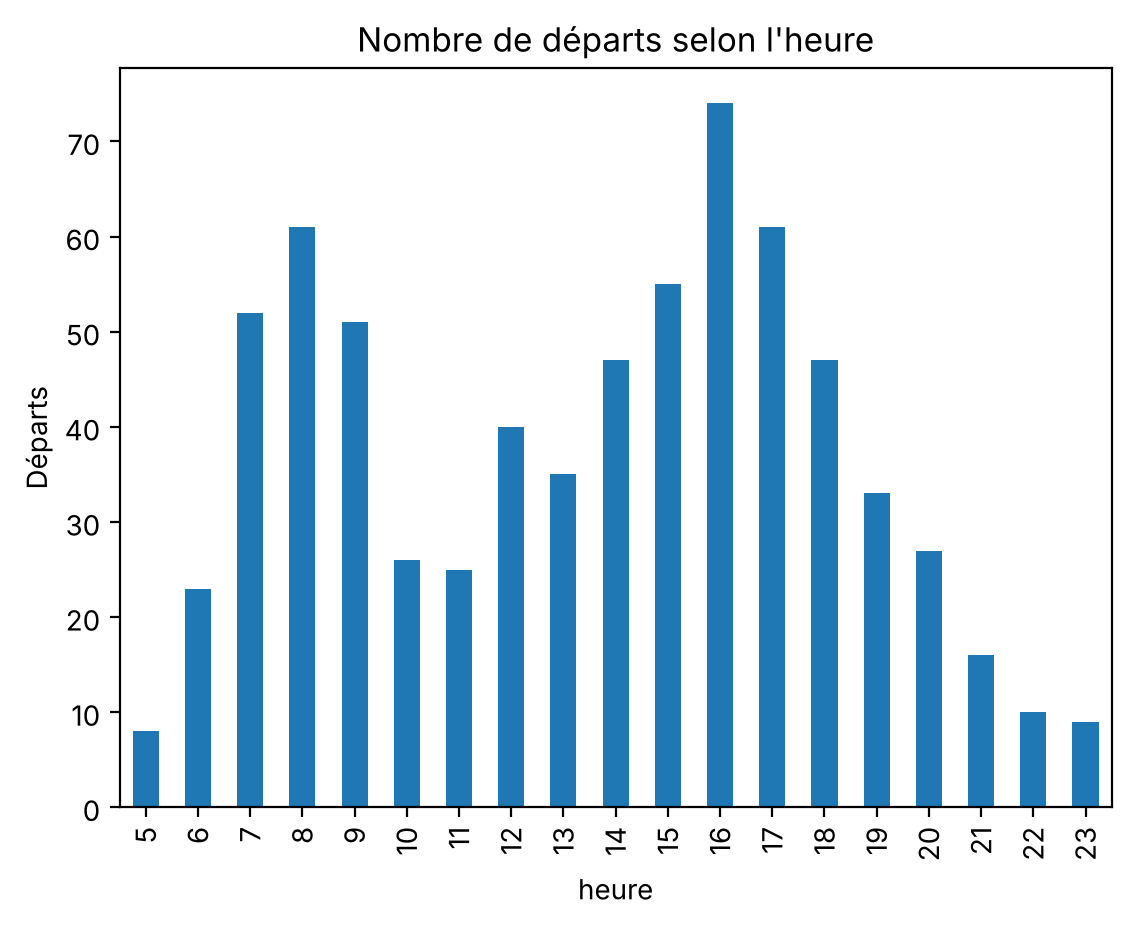

In [10]:
#Nombre de depart selon l'heure 
trajets.groupby("heure").size().plot(kind="bar")
plt.title("Nombre de départs selon l'heure")
plt.ylabel("Départs")
plt.show()

Deux pointes : 16 h (74 départs) et 8 h (61). 8 h est bien une heure chargée.

Part de cases à zéro : 93.9 %


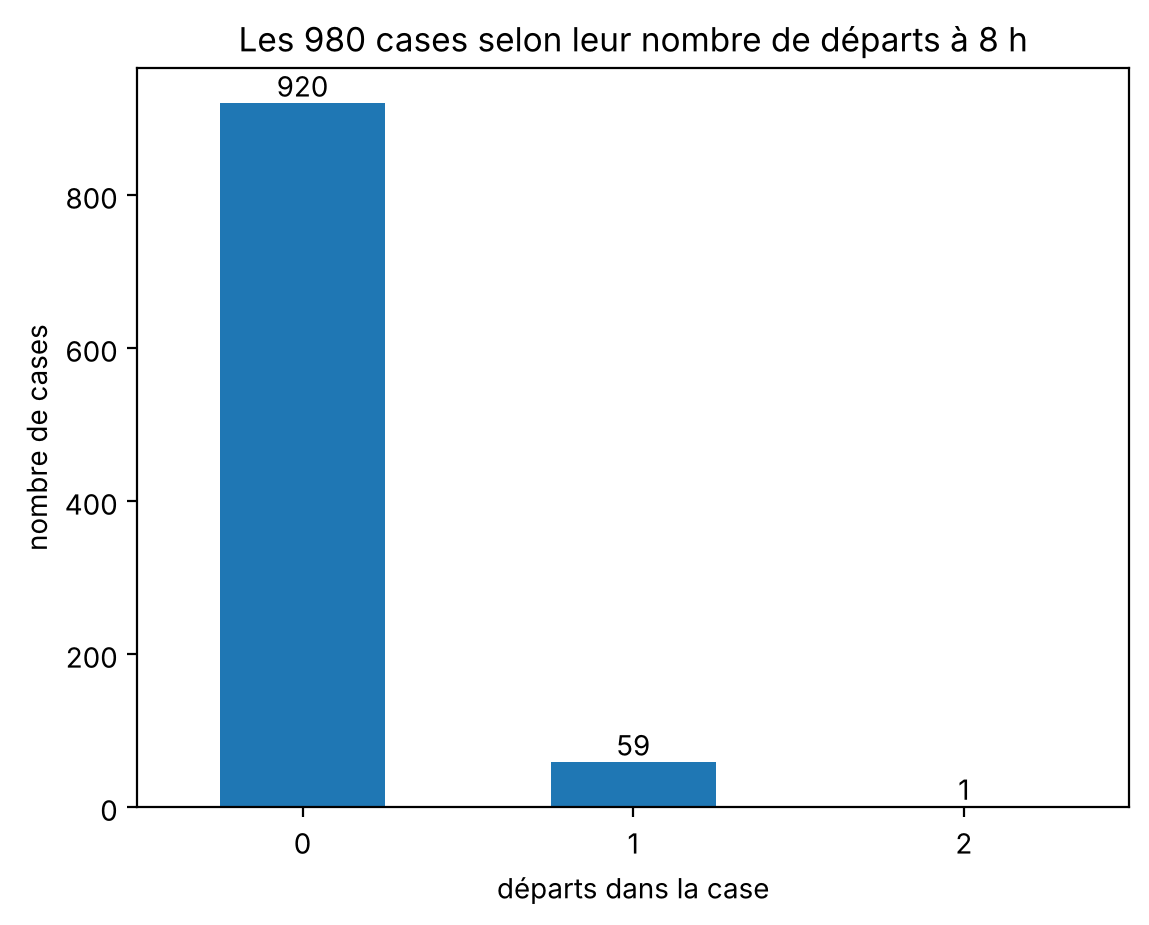

In [11]:
ax = dt["nombre_departs"].value_counts().sort_index().plot(kind="bar")
ax.bar_label(ax.containers[0])
plt.title("Les 980 cases selon leur nombre de départs à 8 h")
plt.xlabel("départs dans la case")
plt.ylabel("nombre de cases")
plt.xticks(rotation=0)
plt.show()

print("Part de cases à zéro :", round((dt["nombre_departs"] == 0).mean() * 100, 1), "%")

920 cases sur 980 sont à zéro (94 %), une seule a 2 départs. Les départs à 8 h sont rares.

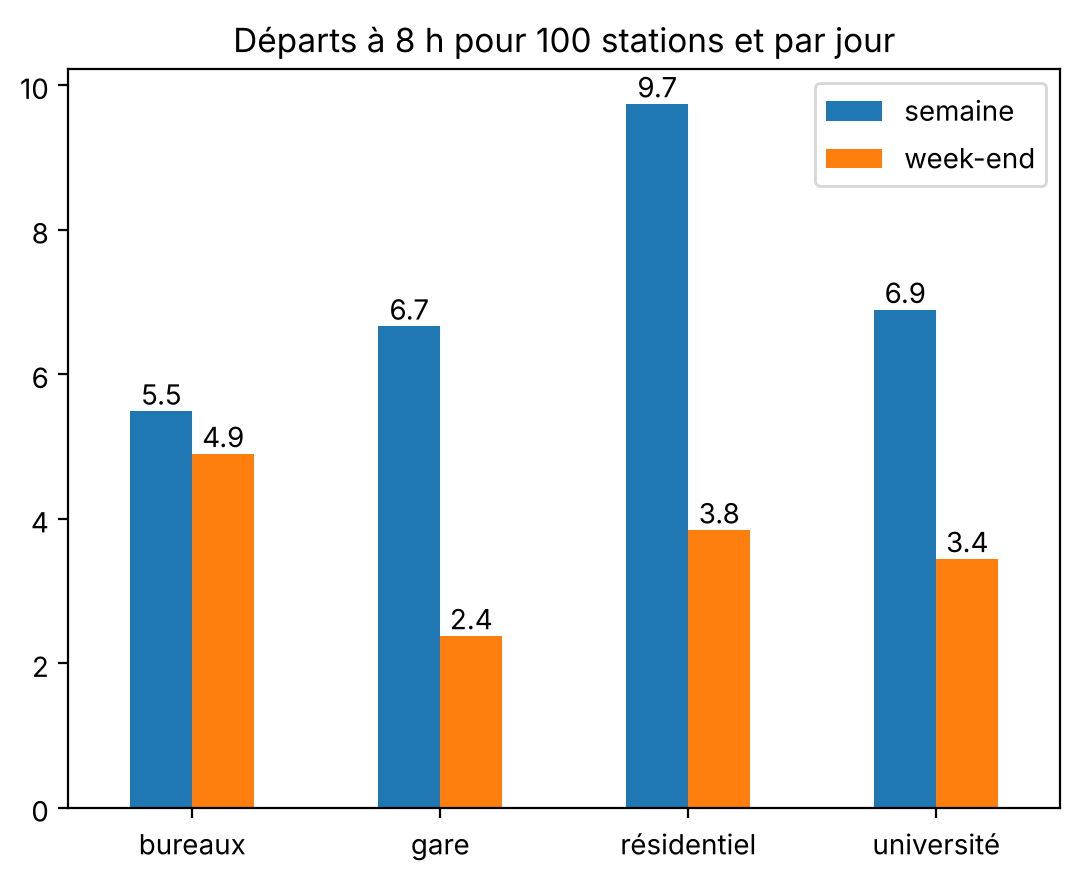

In [12]:
moyennes = dt.pivot_table(index="type_quartier", columns="weekend",
                          values="nombre_departs", aggfunc="mean") * 100
moyennes.columns = ["semaine", "week-end"]

ax = moyennes.plot(kind="bar")
for barres in ax.containers:
    ax.bar_label(barres, fmt="%.1f")   # une décimale
plt.title("Départs à 8 h pour 100 stations et par jour")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

Dans la semaine représentative, les quartiers résidentiels ont le comptage moyen de départs le plus élevé en semaine. Les moyennes sont plus faibles le week-end dans les différents types de quartier, notamment aux gares (6,7 contre 2,4 départs pour 100 stations-jours). Ce sont des constats descriptifs sur la reconstruction, pas une preuve d'un effet causal ou d'une stabilité future.

### Choix des variables

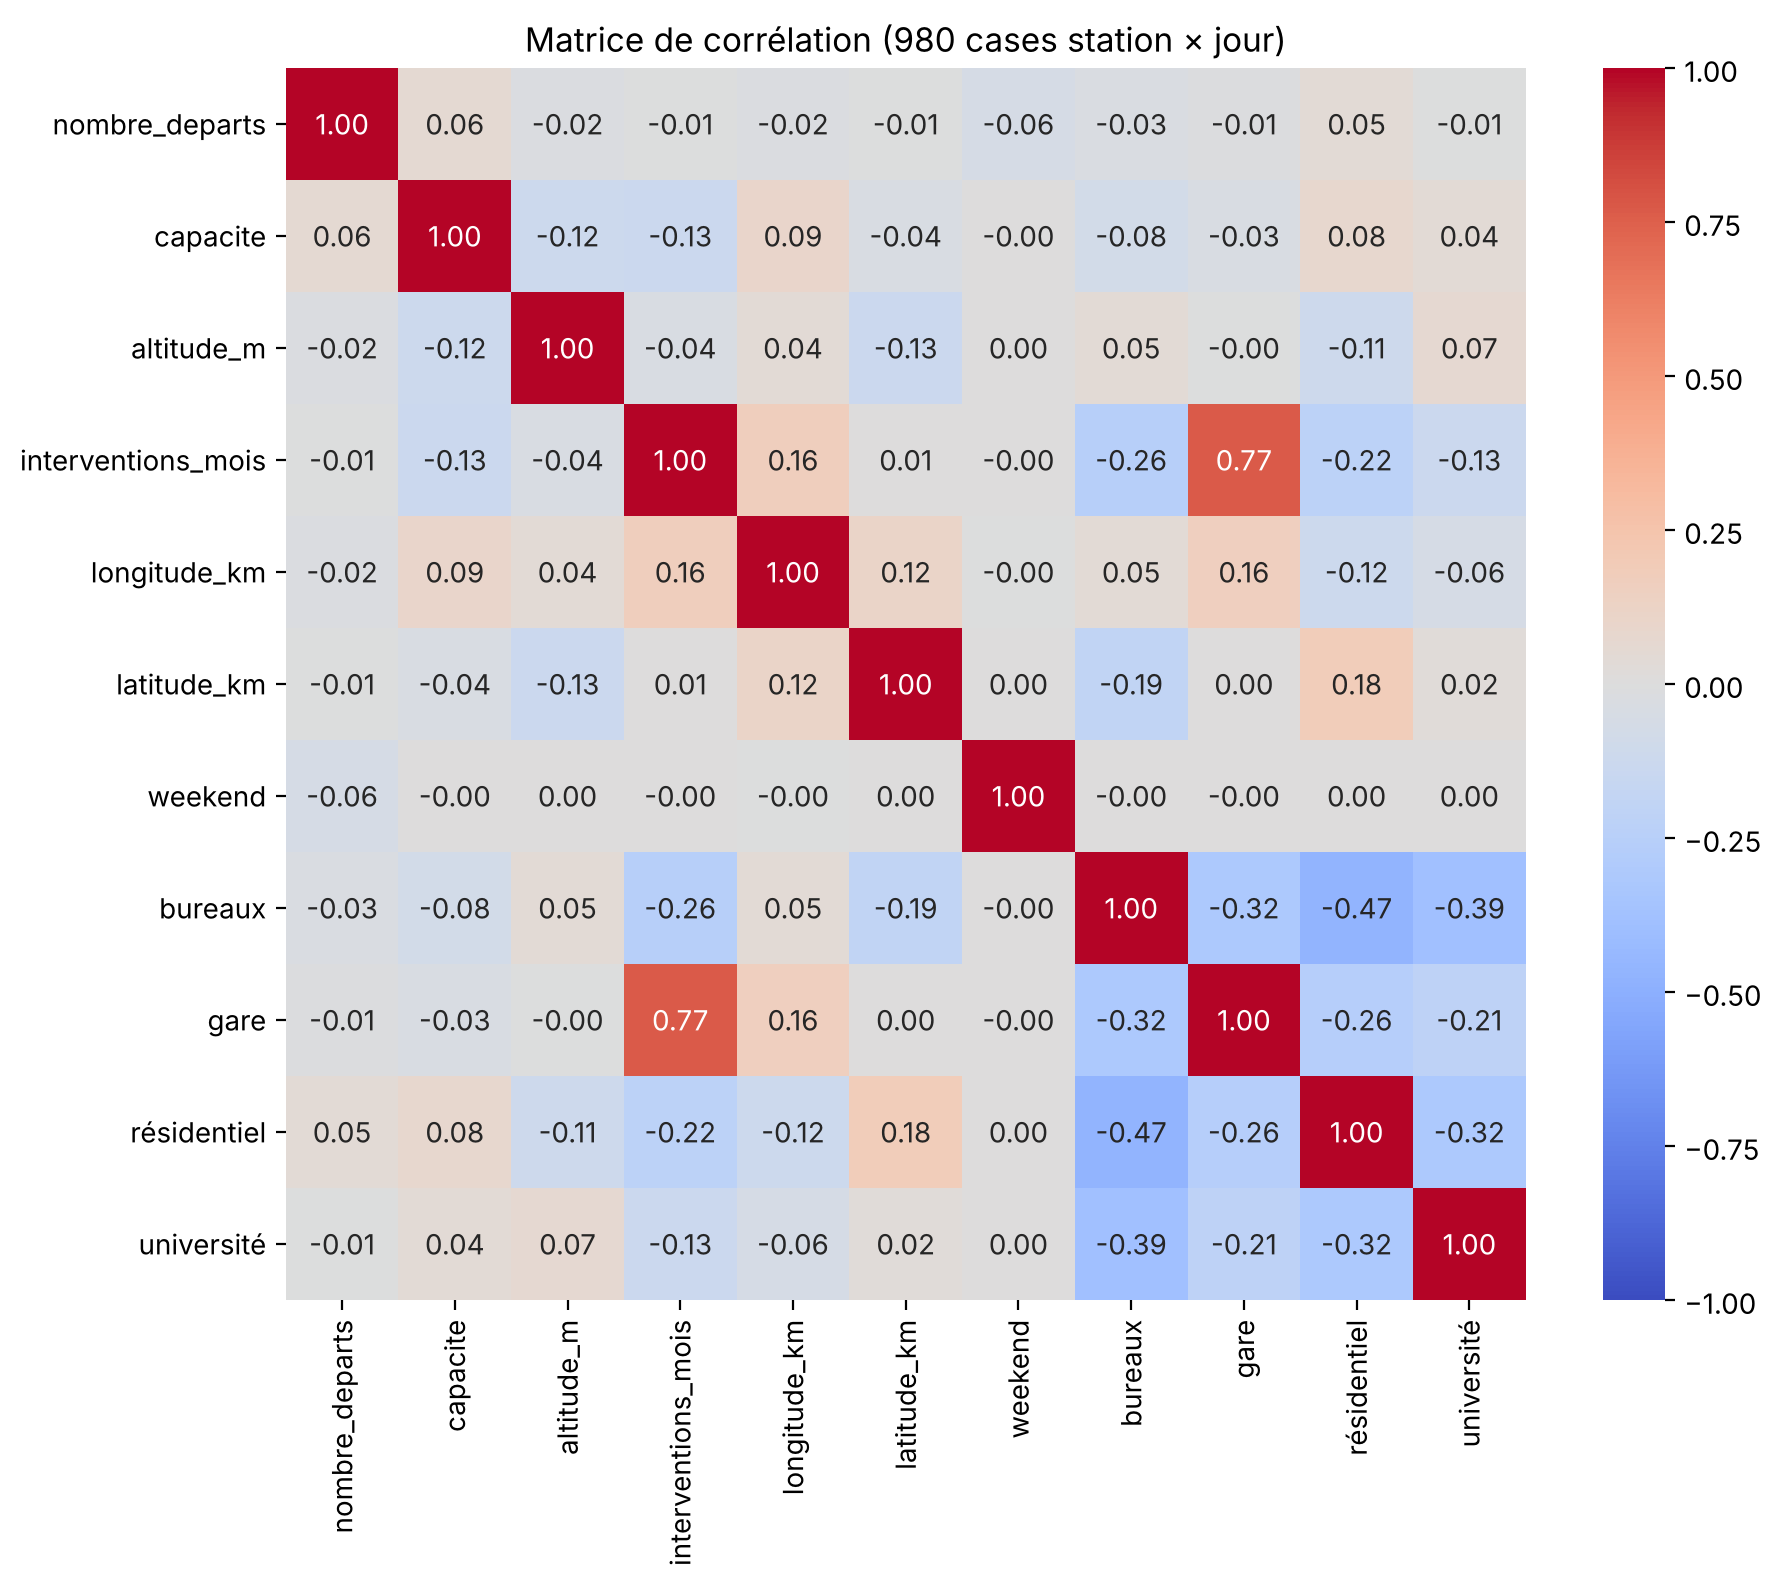

In [13]:
types = pd.get_dummies(dt["type_quartier"], dtype=int)
tableau_corr = pd.concat([dt[["nombre_departs", "capacite", "altitude_m", "interventions_mois",
                              "longitude_km", "latitude_km", "weekend"]], types], axis=1)

plt.figure(figsize=(10, 8))
sns.heatmap(tableau_corr.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Matrice de corrélation (980 cases station × jour)")
plt.show()

Les corrélations linéaires avec `nombre_departs` sont faibles (environ 0,06 au maximum).
- Nous essayons la capacité (+0,06), le week-end (-0,06) et le type de quartier (résidentiel +0,05) comme premières hypothèses explicatives.
- Nous n'incluons pas altitude, longitude, latitude et `interventions_mois` dans ce modèle initial. Leurs faibles corrélations ne démontrent pas leur inutilité : les essais avec d'autres combinaisons ci-dessous complètent cette exploration. Les interventions peuvent aussi refléter la gestion du réseau et leur période n'est pas connue.

La température et la pluie sont enregistrées sur les trajets, sans observation indépendante pour les 920 cases sans départ. Nous ne pouvons donc pas les attribuer à toutes les cases sans hypothèse supplémentaire.

Nous ne donnons pas au modèle la composition future des trajets (abonnements ou vélos), leurs distances, durées et arrivées : ces informations propres aux trajets à prévoir ne sont pas disponibles au moment de la prévision.

### prévoir station par station (régression et kNN)

### Q3 : combien de départs à chaque station ?

**Références :** un modèle n'est utile que s'il fait mieux que « toujours zéro » ou « toujours la moyenne ».

In [14]:
y = dt["nombre_departs"]

prevision_zero = np.zeros(len(y))
rmse_zero = mean_squared_error(y, prevision_zero) ** 0.5

prevision_moyenne = np.full(len(y), y.mean())
rmse_moyenne = mean_squared_error(y, prevision_moyenne) ** 0.5

print("Moyenne des départs par case :", round(y.mean(), 3))
print("RMSE toujours zéro :", round(rmse_zero, 3))
print("RMSE moyenne :", round(rmse_moyenne, 3))

Moyenne des départs par case : 0.062
RMSE toujours zéro : 0.254
RMSE moyenne : 0.246


`get_dummies` transforme le type de quartier en colonnes de 0 et 1. Avec `drop_first=True`, « bureaux » devient la référence. Nous choisissons un modèle fondé sur les caractéristiques des stations plutôt qu'un effet libre pour chaque identifiant, afin de limiter sa complexité avec ces observations rares. Il produit une prévision pour chaque station ; les stations ayant les mêmes caractéristiques reçoivent la même prévision pour un même régime de jour.

In [15]:
#préparation des données
X = pd.get_dummies(dt[["type_quartier"]], drop_first=True, dtype=int)
X["capacite"] = dt["capacite"]
X["weekend"] = dt["weekend"]
y = dt["nombre_departs"]

print(X.head())

   type_quartier_gare  type_quartier_résidentiel  ...  capacite  weekend
0                   1                          0  ...        22        0
1                   1                          0  ...        22        0
2                   1                          0  ...        22        0
3                   1                          0  ...        22        0
4                   1                          0  ...        22        0

[5 rows x 5 columns]


In [16]:
#Séparation train et test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Apprentissage :", len(X_train), "lignes | Test :", len(X_test), "lignes")
print("Départs dans le test :", y_test.sum())

Apprentissage : 784 lignes | Test : 196 lignes
Départs dans le test : 11


In [17]:
# Moyenne : calculée sur l'apprentissage, testée sur le test
prevision_moyenne_test = np.full(len(y_test), y_train.mean())
print("Moyenne -> RMSE :", round(mean_squared_error(y_test, prevision_moyenne_test) ** 0.5, 4))

# Régression
rl = LinearRegression()
rl.fit(X_train, y_train)
rmse_rl_test = mean_squared_error(y_test, rl.predict(X_test)) ** 0.5
print("Régression -> RMSE :", round(rmse_rl_test, 4),
      "| R² test :", round(rl.score(X_test, y_test), 4),
      "| R² apprentissage :", round(rl.score(X_train, y_train), 4))

# kNN (k = 30 pour ce premier essai)
knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=30))
knn.fit(X_train, y_train)
rmse_knn_test = mean_squared_error(y_test, knn.predict(X_test)) ** 0.5
print("kNN -> RMSE :", round(rmse_knn_test, 4), "| R² test :", round(knn.score(X_test, y_test), 4))

Moyenne -> RMSE : 0.2303
Régression -> RMSE : 0.2299 | R² test : 0.0024 | R² apprentissage : 0.0088
kNN -> RMSE : 0.2362 | R² test : -0.0536


Sur ce découpage, la régression a une RMSE de 0,2299 contre 0,2303 pour la baseline moyenne. Le gain est minuscule et son R² presque nul (0,0024). Le kNN obtient une RMSE supérieure (0,2362) et un R² négatif.

Le test ne contient que 11 départs. Nous examinons aussi la validation croisée. Ces découpages évaluent les lignes de la semaine représentative reconstruite et ne constituent pas une validation chronologique des départs de demain.

#### Validation croisée

In [18]:
# 5 paquets, lignes mélangées avant de couper, découpage figé
decoupage = KFold(n_splits=5, shuffle=True, random_state=42)

rl = LinearRegression()

rmse_rl = -cross_val_score(rl, X, y, cv=decoupage, scoring="neg_root_mean_squared_error")
r2_rl = cross_val_score(rl, X, y, cv=decoupage, scoring="r2")

print("RMSE de chaque paquet :", rmse_rl.round(3))
print("RMSE moyen :", round(rmse_rl.mean(), 4))
print("R² moyen :", round(r2_rl.mean(), 4))

RMSE de chaque paquet : [0.23  0.276 0.269 0.204 0.25 ]
RMSE moyen : 0.2458
R² moyen : -0.0185


In [19]:
rmse_moyenne = []

for index_train, index_test in decoupage.split(X):
    # Séparer les lignes de ce tour
    y_train_paquet = y.iloc[index_train]   # les 4 paquets d'apprentissage
    y_test_paquet = y.iloc[index_test]     # le paquet de test

    # La prévision : la moyenne de l'apprentissage, pour toutes les lignes du test
    prevision = np.full(len(y_test_paquet), y_train_paquet.mean())

    # L'erreur de ce tour
    rmse_moyenne.append(mean_squared_error(y_test_paquet, prevision) ** 0.5)

rmse_moyenne = np.array(rmse_moyenne)
print("RMSE de chaque paquet :", rmse_moyenne.round(3))
print("RMSE moyen :", round(rmse_moyenne.mean(), 4))

RMSE de chaque paquet : [0.23  0.275 0.266 0.2   0.251]
RMSE moyen : 0.2445


En validation croisée sur la semaine représentative, la moyenne des RMSE des paquets est légèrement supérieure pour la régression (0,2458) à celle de la baseline moyenne calculée dans chaque entraînement (0,2445). La régression ne surpasse donc pas cette référence à l'échelle station-jour dans cette évaluation.

#### Et avec d'autres variables ?

In [20]:
jeux = {
    "aucune variable": pd.DataFrame({"constante": np.zeros(len(y))}),
    "week-end seul": dt[["weekend"]],
    "type + capacité + week-end": X,
    "toutes les caractéristiques": pd.concat(
        [X, dt[["longitude_km", "latitude_km", "altitude_m", "interventions_mois"]]], axis=1),
}

for nom, X_essai in jeux.items():
    rmse = -cross_val_score(LinearRegression(), X_essai, y, cv=decoupage,
                            scoring="neg_root_mean_squared_error")
    print(nom, "-> RMSE :", round(rmse.mean(), 4))

aucune variable -> RMSE : 0.2445
week-end seul -> RMSE : 0.2447
type + capacité + week-end -> RMSE : 0.2458
toutes les caractéristiques -> RMSE : 0.2471


Aucune des combinaisons testées n'améliore la RMSE de la baseline moyenne dans cette comparaison. Nous examinons aussi la stabilité de l'activité des stations entre deux parties de la semaine représentative. C'est un diagnostic descriptif, pas une condition générale de réussite de tout modèle.

In [21]:
debut = dt[dt["jour"].isin(["lun", "mar", "mer"])].groupby("station_id")["nombre_departs"].sum()
fin = dt[dt["jour"].isin(["jeu", "ven", "sam", "dim"])].groupby("station_id")["nombre_departs"].sum()

print("Corrélation début / fin :", round(debut.corr(fin), 3))
print("Stations avec départ lun-mer -> départs jeu-dim :", round(fin[debut > 0].mean(), 2))
print("Stations sans départ lun-mer -> départs jeu-dim :", round(fin[debut == 0].mean(), 2))

Corrélation début / fin : -0.098
Stations avec départ lun-mer -> départs jeu-dim : 0.14
Stations sans départ lun-mer -> départs jeu-dim : 0.25


La corrélation début-fin est faible et légèrement négative dans la semaine reconstruite. Cette comparaison ne met pas en évidence une activité station par station stable entre ces deux parties, sans prouver qu'aucune régularité temporelle n'existerait dans un historique daté.

In [22]:
autres_heures = trajets[trajets["heure"] != 8].groupby("station_depart").size()
autres_heures = autres_heures.reindex(stations["station_id"], fill_value=0)
a_8h = trajets_8h.groupby("station_depart").size().reindex(stations["station_id"], fill_value=0)

print("Corrélation autres heures / 8 h :", round(autres_heures.corr(a_8h), 3))

Corrélation autres heures / 8 h : 0.009


La corrélation avec l'activité aux autres heures est également faible (0,009). Ce diagnostic ne montre pas de relation linéaire exploitable dans cette comparaison ; il ne démontre pas que les départs à 8 h sont aléatoires.

#### Et avec 7 h – 9 h, pour avoir plus de trajets ?

In [23]:
trajets_7_9 = trajets[trajets["heure"].isin([7, 8, 9])]
print("trajets entre 7 h et 9 h :", len(trajets_7_9))

lignes = []
for station in stations["station_id"]:
    for jour in jours:
        departs = trajets_7_9[
            (trajets_7_9["station_depart"] == station)
            & (trajets_7_9["jour"] == jour)
        ]
        lignes.append({"station_id": station, "jour": jour, "nombre_departs": len(departs)})

dt_7_9 = pd.DataFrame(lignes).merge(stations, on="station_id")
dt_7_9["weekend"] = dt_7_9["jour"].isin(["sam", "dim"]).astype(int)
y_7_9 = dt_7_9["nombre_departs"]

X_7_9 = pd.get_dummies(dt_7_9[["type_quartier"]], drop_first=True, dtype=int)
X_7_9["capacite"] = dt_7_9["capacite"]
X_7_9["weekend"] = dt_7_9["weekend"]
X_vide = pd.DataFrame({"constante": np.zeros(len(y_7_9))})   # aucune variable = la moyenne

rmse_moy_7_9 = -cross_val_score(LinearRegression(), X_vide, y_7_9, cv=decoupage,
                                scoring="neg_root_mean_squared_error")
rmse_rl_7_9 = -cross_val_score(LinearRegression(), X_7_9, y_7_9, cv=decoupage,
                               scoring="neg_root_mean_squared_error")
print("moyenne -> RMSE :", round(rmse_moy_7_9.mean(), 4))
print("régression -> RMSE :", round(rmse_rl_7_9.mean(), 4))

trajets entre 7 h et 9 h : 164
moyenne -> RMSE : 0.4151
régression -> RMSE : 0.4152


Le créneau élargi contient 164 trajets au lieu de 61, mais la régression et la baseline moyenne obtiennent des RMSE très proches (0,4152 contre 0,4151). Cet essai ne montre pas de gain à élargir le créneau avec cette construction et ce modèle. Comme Q3 porte sur 8 h, nous conservons la cible initiale.

#### kNN : choix de k

k = 5 -> RMSE moyen : 0.274
k = 10 -> RMSE moyen : 0.2585
k = 20 -> RMSE moyen : 0.2525
k = 30 -> RMSE moyen : 0.2513
k = 50 -> RMSE moyen : 0.2479
k = 75 -> RMSE moyen : 0.2471
k = 100 -> RMSE moyen : 0.2468
k = 150 -> RMSE moyen : 0.246


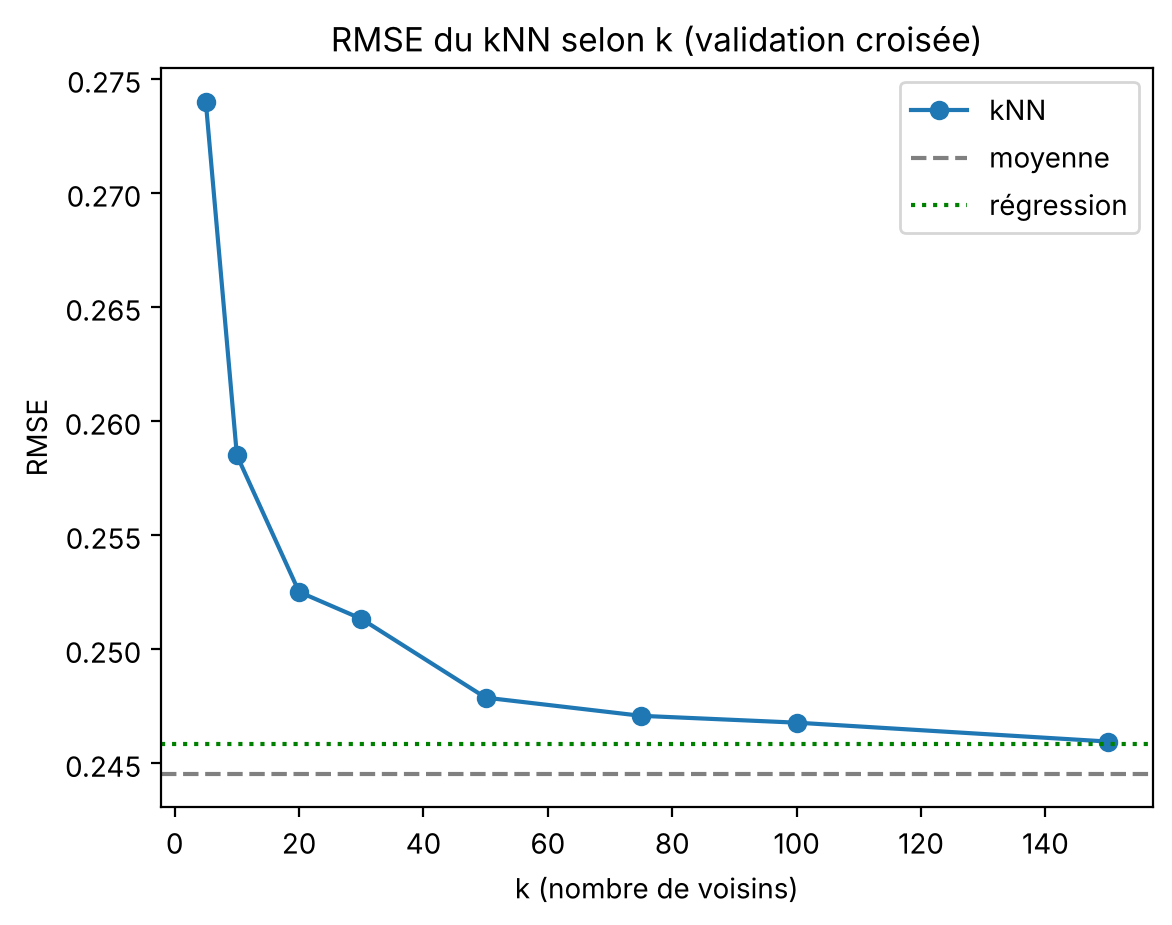

In [24]:
valeurs_k = [5, 10, 20, 30, 50, 75, 100, 150]
rmse_par_k = []

for k in valeurs_k:
    knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
    rmse_knn = -cross_val_score(knn, X, y, cv=decoupage, scoring="neg_root_mean_squared_error")
    rmse_par_k.append(rmse_knn.mean())
    print("k =", k, "-> RMSE moyen :", round(rmse_knn.mean(), 4))

plt.plot(valeurs_k, rmse_par_k, marker="o", label="kNN")
plt.axhline(rmse_moyenne.mean(), color="gray", linestyle="--", label="moyenne")
plt.axhline(rmse_rl.mean(), color="green", linestyle=":", label="régression")
plt.title("RMSE du kNN selon k (validation croisée)")
plt.xlabel("k (nombre de voisins)")
plt.ylabel("RMSE")
plt.legend()
plt.show()

Parmi les valeurs testées sur ces données, la RMSE du kNN se rapproche de celle de la baseline lorsque k augmente, sans montrer d'amélioration. Nous conservons k = 100 pour les comparaisons suivantes, sans le présenter comme l'optimum de cette grille : k = 150 a une RMSE légèrement plus faible. Ces choix exploratoires n'ont pas de test final indépendant.

In [25]:
valeurs_k = [10, 30, 50, 100]

for nom, X_essai in jeux.items():
    resultats = []
    for k in valeurs_k:
        knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=k))
        rmse = -cross_val_score(knn, X_essai, y, cv=decoupage,
                                scoring="neg_root_mean_squared_error")
        resultats.append(rmse.mean())

    meilleur = min(resultats)
    meilleur_k = valeurs_k[resultats.index(meilleur)]
    print(nom, "-> meilleur k :", meilleur_k, "| RMSE :", round(meilleur, 4))

aucune variable -> meilleur k : 30 | RMSE : 0.2445
week-end seul -> meilleur k : 50 | RMSE : 0.2451
type + capacité + week-end -> meilleur k : 100 | RMSE : 0.2468
toutes les caractéristiques -> meilleur k : 100 | RMSE : 0.2469


**Bilan Q3 (partie 1) :** parmi les combinaisons testées, ni la régression ni le kNN ne montrent de gain par rapport à la baseline moyenne à l'échelle station-jour. Les variables disponibles ne permettent pas de prédire efficacement les départs avec ces modèles dans cette évaluation. Nous n'en déduisons pas que tous les modèles échoueraient ni que les départs sont aléatoires.

### Q4 : quelles limites selon les situations ?

On récupère pour chaque ligne une prévision faite par un modèle qui n'a pas utilisé cette ligne pour apprendre (validation croisée). Cela fournit des erreurs hors apprentissage sur la semaine représentative. Cela ne remplace pas une validation chronologique sur de nouvelles journées complètes.

In [26]:
dt["prevision_moyenne"] = 0.0
dt["prevision_rl"] = 0.0
dt["prevision_knn"] = 0.0

for index_train, index_test in decoupage.split(X):
    X_tr, y_tr = X.iloc[index_train], y.iloc[index_train]
    X_te = X.iloc[index_test]
    lignes_test = dt.index[index_test]

    dt.loc[lignes_test, "prevision_moyenne"] = y_tr.mean()
    dt.loc[lignes_test, "prevision_rl"] = LinearRegression().fit(X_tr, y_tr).predict(X_te)
    knn = make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=100))
    dt.loc[lignes_test, "prevision_knn"] = knn.fit(X_tr, y_tr).predict(X_te)

**Le week-end**

In [27]:
semaine = dt[dt["weekend"] == 0]
weekend = dt[dt["weekend"] == 1]

print("SEMAINE")
print("moyenne :", round(mean_squared_error(semaine["nombre_departs"], semaine["prevision_moyenne"]) ** 0.5, 4))
print("régression :", round(mean_squared_error(semaine["nombre_departs"], semaine["prevision_rl"]) ** 0.5, 4))
print("kNN :", round(mean_squared_error(semaine["nombre_departs"], semaine["prevision_knn"]) ** 0.5, 4))

print("WEEK-END")
print("moyenne :", round(mean_squared_error(weekend["nombre_departs"], weekend["prevision_moyenne"]) ** 0.5, 4))
print("régression :", round(mean_squared_error(weekend["nombre_departs"], weekend["prevision_rl"]) ** 0.5, 4))
print("kNN :", round(mean_squared_error(weekend["nombre_departs"], weekend["prevision_knn"]) ** 0.5, 4))

SEMAINE
moyenne : 0.2636
régression : 0.2648
kNN : 0.2663
WEEK-END
moyenne : 0.1954
régression : 0.1966
kNN : 0.1963


Dans les deux sous-groupes observés, semaine et week-end, les modèles ne surpassent pas la baseline sur la RMSE à l'échelle station-jour. Ce constat ne permet pas à lui seul de juger les jours exceptionnels, qui ne sont pas identifiés.

**Quand il y a vraiment un départ**

In [28]:
avec_depart = dt[dt["nombre_departs"] > 0]
sans_depart = dt[dt["nombre_departs"] == 0]

print("Prévision moyenne de la régression :")
print("cases AVEC un départ :", round(avec_depart["prevision_rl"].mean(), 3))
print("cases SANS départ :", round(sans_depart["prevision_rl"].mean(), 3))

Prévision moyenne de la régression :
cases AVEC un départ : 0.062
cases SANS départ : 0.063


Les prévisions moyennes de la régression sont très proches pour les cases avec et sans départ (0,062 contre 0,063). Le modèle distingue donc peu les cases actives des cases sans activité dans cette évaluation. Ce découpage utilise les observations après coup ; il n'est pas une information disponible pour prévoir demain.

**Bilan Q4 (partie 1) :** la précision à l'échelle station-jour est déjà limitée dans l'évaluation globale. On ne peut pas conclure à une robustesse sur les jours particuliers sans observations datées de ces situations.

## Autre solution, par zone et par jour

Nous conservons les données et les modèles, puis examinons une autre échelle : la somme des prévisions par zone et par jour. L'agrégation peut réduire certaines erreurs individuelles, sans garantir qu'elles se compensent. Nous comparons donc les modèles à leur baseline agrégée sur les mêmes groupes.

Cette estimation complète l'analyse station par station ; elle ne démontre pas que l'on sait répartir précisément les départs entre toutes les stations d'une zone.

### Q3 : estimations sous l'hypothèse d'une semaine représentative

**Totaux par jour (tout le réseau)**

In [29]:
totaux_jour = dt.groupby("jour")[["nombre_departs", "prevision_moyenne",
                                  "prevision_rl", "prevision_knn"]].sum().reindex(jours)
print(totaux_jour.round(1))
for colonne in ["prevision_moyenne", "prevision_rl", "prevision_knn"]:
    erreur = mean_squared_error(totaux_jour["nombre_departs"], totaux_jour[colonne]) ** 0.5
    r2 = r2_score(totaux_jour["nombre_departs"], totaux_jour[colonne])
    print(colonne, "RMSE :", round(erreur, 2), "R² :", round(r2, 2))

      nombre_departs  prevision_moyenne  prevision_rl  prevision_knn
jour                                                                
lun                7                8.7          10.1           10.0
mar               11                8.8          10.1           10.0
mer               11                8.7          10.1           10.1
jeu                8                8.7           9.9            9.9
ven               13                8.7          10.2           10.2
sam                4                8.7           5.7            7.3
dim                7                8.7           5.8            7.2
prevision_moyenne RMSE : 2.86 R² : 0.0
prevision_rl RMSE : 1.98 R² : 0.52
prevision_knn RMSE : 2.18 R² : 0.42


Sur les totaux journaliers reconstruits, les prévisions agrégées de la régression ont une RMSE de 1,98 départ contre 2,86 pour la baseline agrégée (R² de 0,52 contre environ 0). Le modèle produit des prévisions plus faibles le week-end, plus proches de ces totaux observés. Cela ne démontre pas sa précision sur de futures dates.

**Les zones, avec le K-Means**

2 inertie : 596.9 silhouette : 0.564
3 inertie : 183.4 silhouette : 0.71
4 inertie : 117.8 silhouette : 0.718
5 inertie : 86.7 silhouette : 0.669
6 inertie : 77.8 silhouette : 0.58
7 inertie : 69.1 silhouette : 0.465
groupe
0    50
1    54
2    36
Name: count, dtype: int64
   longitude_km  latitude_km
0           5.1          6.4
1           2.4          2.5
2           8.0          3.0


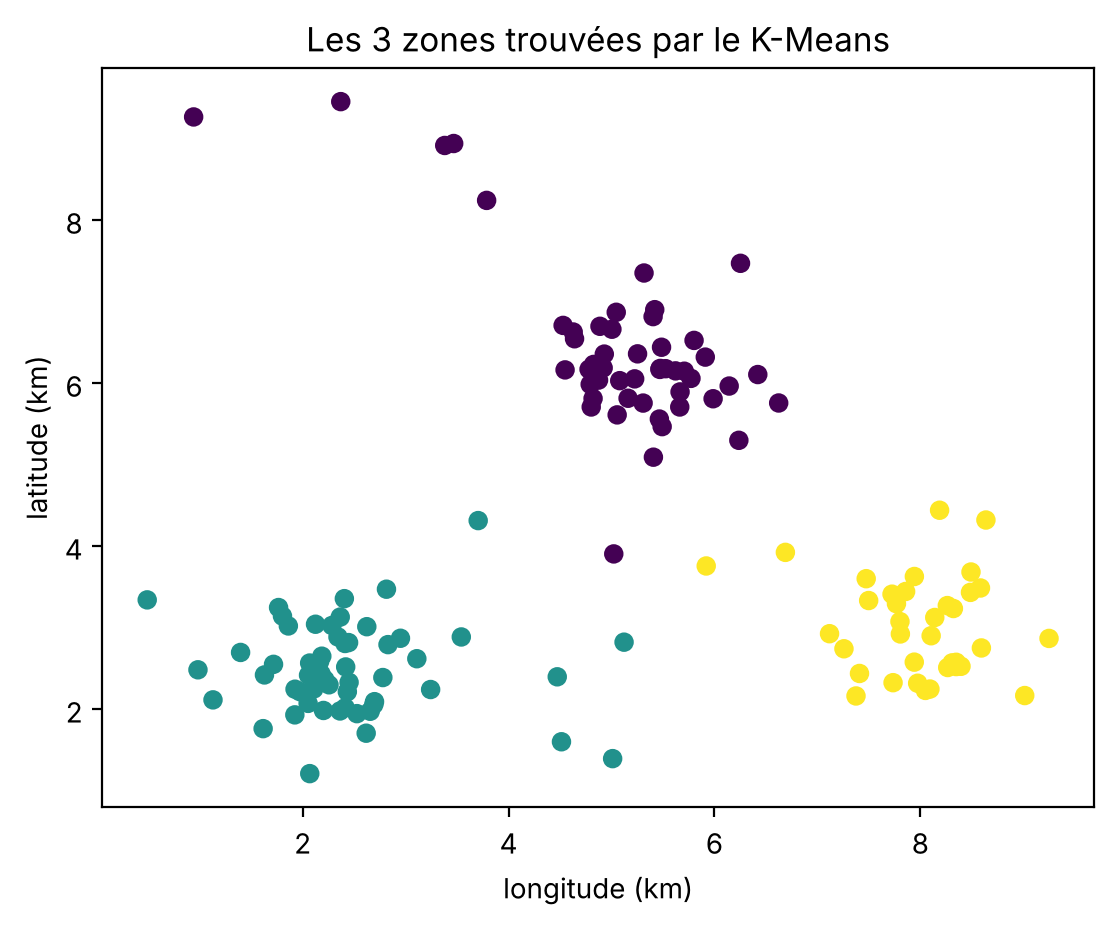

In [30]:
positions = stations[["longitude_km", "latitude_km"]]

# 1. Choisir k : coude (inertie) + silhouette
for k in range(2, 8):
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(positions)
    print(k, "inertie :", round(kmeans.inertia_, 1),
          "silhouette :", round(silhouette_score(positions, kmeans.labels_), 3))

# 2. K-Means avec k = 3, puis on ajoute le groupe dans dt
kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans.fit(positions)
groupes = pd.DataFrame({"station_id": stations["station_id"], "groupe": kmeans.labels_})
dt = dt.drop(columns="groupe", errors="ignore")   # évite les doublons si on relance la cellule
dt = dt.merge(groupes, on="station_id")

print(groupes["groupe"].value_counts().sort_index())
print(pd.DataFrame(kmeans.cluster_centers_, columns=["longitude_km", "latitude_km"]).round(1))

# 3. Carte des zones
plt.scatter(stations["longitude_km"], stations["latitude_km"], c=kmeans.labels_, cmap="viridis")
plt.title("Les 3 zones trouvées par le K-Means")
plt.xlabel("longitude (km)")
plt.ylabel("latitude (km)")
plt.show()

Nous retenons **k = 3** comme compromis entre le coude de l'inertie, la simplicité et des groupes de 50, 54 et 36 stations. Pour k = 4, la silhouette est légèrement supérieure, mais un groupe ne contient que 5 stations. Ce choix de regroupement ne détermine pas le nombre ni la taille des camionnettes.

Les deux coordonnées sont en kilomètres ; nous conservons la distance géographique sur le plan sans standardisation. D'après les centres, groupe 0 = **nord**, groupe 1 = **sud-ouest**, groupe 2 = **sud-est**.

**Totaux par zone et par jour**

In [31]:
totaux = dt.groupby(["groupe", "jour"])[["nombre_departs", "prevision_moyenne",
                                         "prevision_rl", "prevision_knn"]].sum()
for colonne in ["prevision_moyenne", "prevision_rl", "prevision_knn"]:
    erreur = mean_squared_error(totaux["nombre_departs"], totaux[colonne]) ** 0.5
    r2 = r2_score(totaux["nombre_departs"], totaux[colonne])
    print(colonne, "RMSE :", round(erreur, 2), "R² :", round(r2, 2))

prevision_moyenne RMSE : 1.62 R² : 0.16
prevision_rl RMSE : 1.42 R² : 0.36
prevision_knn RMSE : 1.43 R² : 0.34


Sur les totaux zone-jour disponibles, la régression agrégée obtient une meilleure RMSE que la baseline agrégée (1,42 contre 1,62 ; R² de 0,36 contre 0,16). Ce gain est observé sur la semaine représentative, sans test sur de nouvelles dates. Les RMSE par zone et par station ne sont pas directement comparables car elles portent sur des quantités différentes.

**Nous retenons la régression pour cette estimation agrégée** : elle obtient ici une RMSE légèrement inférieure à celle du kNN et ses coefficients sont lisibles. Le résultat proche du kNN est une comparaison sur les mêmes données, pas une confirmation indépendante de fiabilité.

**Estimation pour demain sous l’hypothèse d’une semaine représentative**

In [32]:
# On entraîne la régression sur toutes les données
rl = LinearRegression()
rl.fit(X, y)

# Les 140 stations, avec les mêmes colonnes que X
demain = pd.get_dummies(stations[["type_quartier"]], drop_first=True, dtype=int)
demain["capacite"] = stations["capacite"]

prevision_demain = stations[["station_id"]].copy()
prevision_demain["groupe"] = kmeans.labels_

demain["weekend"] = 0
prevision_demain["semaine"] = rl.predict(demain)
demain["weekend"] = 1
prevision_demain["week-end"] = rl.predict(demain)

print(prevision_demain.groupby("groupe")[["semaine", "week-end"]].sum().round(1))
print("Total réseau :", prevision_demain[["semaine", "week-end"]].sum().round(1).to_dict())

        semaine  week-end
groupe                   
0           3.7       2.1
1           3.9       2.1
2           2.4       1.3
Total réseau : {'semaine': 10.0, 'week-end': 5.5}


**Réponse Q3 :** sous l'hypothèse d'une semaine représentative, le modèle estime pour demain à 8 h environ **10 départs** sur le réseau si c'est un jour de semaine (3,7 au nord, 3,9 au sud-ouest et 2,4 au sud-est), et environ **5,5** si c'est le week-end. Ce sont des estimations conditionnelles issues de la reconstruction, pas des départs futurs validés.

### Q4 : notre solution tient-elle les jours particuliers ?

**Le week-end**

In [33]:
semaine = dt[dt["weekend"] == 0]
weekend = dt[dt["weekend"] == 1]

print("SEMAINE - réel :", semaine["nombre_departs"].sum(),
      "| moyenne :", round(semaine["prevision_moyenne"].sum(), 1),
      "| régression :", round(semaine["prevision_rl"].sum(), 1))
print("WEEK-END - réel :", weekend["nombre_departs"].sum(),
      "| moyenne :", round(weekend["prevision_moyenne"].sum(), 1),
      "| régression :", round(weekend["prevision_rl"].sum(), 1))

SEMAINE - réel : 50 | moyenne : 43.6 | régression : 50.3
WEEK-END - réel : 11 | moyenne : 17.4 | régression : 11.4


Pour les lignes de week-end évaluées, le total prévu par la régression (11,4) est plus proche du total observé (11) que celui de la baseline (17,4). Cela décrit la calibration agrégée sur ces données et peut masquer des erreurs qui se compensent entre stations ou jours. Ce résultat ne suffit pas à établir la robustesse sur de futurs week-ends ou des jours exceptionnels.

**Test de résistance : transférer un modèle entraîné en semaine au week-end**

In [34]:
# On entraîne la régression sur la semaine seulement (sans la colonne weekend)
X_semaine = X[dt["weekend"] == 0].drop(columns="weekend")
X_weekend = X[dt["weekend"] == 1].drop(columns="weekend")

rl_semaine = LinearRegression()
rl_semaine.fit(X_semaine, semaine["nombre_departs"])
print("Week-end prévu par un modèle qui n'a vu que la semaine :",
      round(rl_semaine.predict(X_weekend).sum(), 1), "| réel :", weekend["nombre_departs"].sum())

Week-end prévu par un modèle qui n'a vu que la semaine : 20.0 | réel : 11


Dans cet essai, le modèle entraîné seulement sur les lignes de semaine, sans variable week-end, prévoit 20 départs pour les lignes de week-end contre 11 observés. Cela illustre une limite lors du transfert entre deux régimes. Cet essai ne mesure pas les performances sur les jours fériés ou les grèves et ne permet pas d'affirmer qu'une prévision s'y écroulerait.

**La pluie** (en semaine, sur les trajets eux-mêmes)

In [35]:
trajets_semaine = trajets[~trajets["jour"].isin(["sam", "dim"])]

# Pour chaque météo, le % des trajets partis à chaque heure
repartition = pd.crosstab(trajets_semaine["pluie"], trajets_semaine["heure"], normalize="index") * 100
print(repartition[[7, 8, 9]].round(1))

heure     7    8    9
pluie                
non     6.5  9.6  6.5
oui    10.0  6.9  6.9


Parmi les trajets de semaine enregistrés, la part à 8 h est de 6,9 % sous la pluie contre 9,6 % sans pluie ; celle à 7 h est de 10 % contre 6,5 %. Cette différence descriptive suggère une piste à vérifier, mais ne démontre pas que la pluie avance les départs ni qu'elle réduit leur nombre par journée.

Nous ne connaissons pas le nombre de jours ou d'heures d'exposition à chaque météo, et seuls 9 départs à 8 h sont enregistrés sous la pluie en semaine. On ne peut donc ni mesurer une erreur de prévision par jour de pluie ni justifier un passage systématique des camionnettes avant 7 h avec ce seul tableau.

**Le froid et la chaleur**

In [36]:
trajets["meteo"] = "doux"
trajets.loc[trajets["temperature_c"] < 5, "meteo"] = "froid"
trajets.loc[trajets["temperature_c"] > 25, "meteo"] = "chaud"

trajets["a_8h"] = trajets["heure"] == 8
print(pd.crosstab(trajets["meteo"], trajets["a_8h"]))

a_8h   False  True 
meteo              
chaud     32      5
doux     549     48
froid     58      8


Seulement 8 départs à 8 h par temps froid et 5 par temps chaud : trop peu pour conclure.

**Les jours les plus chargés**

In [37]:
print(totaux[["nombre_departs", "prevision_rl"]].sort_values("nombre_departs", ascending=False).round(1).head(5))

charges = totaux[totaux["nombre_departs"] >= 5]
normaux = totaux[totaux["nombre_departs"] < 5]

print("JOURS CHARGÉS - réel :", charges["nombre_departs"].sum(),
      "| régression :", round(charges["prevision_rl"].sum(), 1))
print("JOURS NORMAUX - réel :", normaux["nombre_departs"].sum(),
      "| régression :", round(normaux["prevision_rl"].sum(), 1))

# Le pire jour observé dans chaque zone
pic = totaux.groupby("groupe")["nombre_departs"].max()
print("Maximum observé en un jour par zone :", pic.to_dict())

             nombre_departs  prevision_rl
groupe jour                              
1      mar                7           3.9
0      ven                6           3.9
1      ven                5           3.9
0      mer                5           3.5
       jeu                5           3.6
JOURS CHARGÉS - réel : 28 | régression : 18.8
JOURS NORMAUX - réel : 33 | régression : 43.0
Maximum observé en un jour par zone : {0: 6, 1: 7, 2: 3}


Dans les groupes-jours classés comme chargés après observation, la régression sous-estime le total (18,8 prévus contre 28). Cela montre une limite sur les fortes valeurs observées, sans identifier des événements exceptionnels datés ni comparer plusieurs occurrences d'un même mardi.

Les maximums observés par zone (6 au nord, 7 au sud-ouest et 3 au sud-est) peuvent servir de repères pour un scénario de prudence. Ils ne garantissent pas la couverture de futurs pics et ne déterminent pas le chargement nécessaire sans connaître les stocks, les arrivées et les capacités des véhicules.

## Conclusion

**Q3 :** sous l'hypothèse d'une semaine représentative, ni la régression ni le kNN ne surpassent la baseline moyenne à l'échelle station-jour dans les essais réalisés. Nous n'en déduisons pas que les départs sont aléatoires. Nous avons donc conservé les prévisions individuelles et exploré leur agrégation dans trois zones obtenues par K-Means. à l'échelle zone-jour, la régression obtient une meilleure RMSE que la baseline agrégée sur les données disponibles (1,42 contre 1,62).

Sous cette même hypothèse, les estimations pour demain à 8 h sont d'environ 10 départs sur le réseau un jour de semaine (3,7 au nord, 3,9 au sud-ouest et 2,4 au sud-est), ou 5,5 le week-end. Elles ne constituent pas une prévision chronologique validée et ne démontrent pas la répartition précise entre stations.

**Q4 :** le total prévu pour les lignes de week-end est proche du total observé (11,4 contre 11), mais ce résultat agrégé ne prouve pas une robustesse future. Les groupes-jours chargés sont sous-estimés (18,8 contre 28). Le transfert semaine vers week-end est moins précis, ce qui illustre une limite sans démontrer un échec sur les jours fériés ou les grèves. La comparaison des trajets selon la pluie reste descriptive et ne permet pas de conclure à un décalage causal des départs vers 7 h.

**Pour les camionnettes :** les trois zones peuvent servir de base à l'étude des tournées. Les deux départs maximums par station et les pics observés par zone sont des repères sur cet échantillon, pas des garanties sur les besoins futurs. Les données ne suffisent pas à fixer une camionnette par zone, un stock de vélos à déplacer ou un horaire de passage par temps de pluie.

**Limites :** absence de dates complètes et de durée de collecte connue, semaine représentative construite par hypothèse, convention de zéro pour les cases sans enregistrement, seulement 61 trajets à 8 h et absence des stocks de vélos par station. Les validations croisées portent sur les données reconstruites ; elles ne remplacent pas un test chronologique indépendant.

**Recommandations :** recueillir des trajets datés sur plusieurs mois, une météo indépendante par date et heure, les stocks et arrivées par station, ainsi que les contraintes des camionnettes. Ces informations permettraient de vérifier les hypothèses, de tester les prévisions sur de nouvelles journées et de dimensionner les tournées.